# Ideas

1. **Image Preprocessing**
    -   **Dataset Augmentation**
        *   x10 the training dataset
    -   Grayscaling
        *   Primarily reduce the computational power
2. **Intuitively Group Age Classes**
    -   Roblox: 5-8, 9-12, 13-15, 16-17, 18-20, and 21+
    -   Business-wise, we have to add more label for 21+
    -   Suggestion for 21+ group: 21-27, 28-45, 46-65, 66+
        -   21-27 years: Categorized as mature adults.
        -   28-45 years: Representing the adult stage of life.
        -   46-65 years: Distinguished by the appearance of more pronounced aging features.
        -   66+ years: Represented by features like graying hair and aging skin.
3. Use CNN-Based Deep Learning Aproach


Concluded labels: 1-4, 5-8, 9-12, 13-15, 16-17, 18-20, 21-27, 28-45, 46-65, 66+

# Import Libraries and Setup Environments

In [14]:
# Standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from keras import mixed_precision, layers, models
from keras.models import Sequential, Model
from keras.layers import Conv2D, MaxPooling2D, AveragePooling2D, GlobalAveragePooling2D, Flatten, Dense, Dropout, Input, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img # From old Keras' API. For data augmentation, Keras has imported a new API in TensorFlow 2.x. So, we can use it directly from TensorFlow.
from keras.utils import to_categorical, plot_model
from keras.optimizers import SGD, Adam
from keras.callbacks import ReduceLROnPlateau, EarlyStopping
from keras.applications import VGG16, MobileNetV2
from keras.applications.vgg16 import preprocess_input as vgg_preprocess
from keras.applications.mobilenet_v2 import preprocess_input as mobile_preprocess

# Others:
from pathlib import Path
import os
#import cv2
from tqdm.notebook import tqdm
import imagehash 
from PIL import Image

In [15]:
gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("GPU devices:", gpus)

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [16]:
# This will reduce the VRAM consumed
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
    print("GPU Memory Growth Enabled!")

GPU Memory Growth Enabled!


In [17]:
# For strong GPUs, execute this code cell to turn on FP16 and reduce VRAM usage consumed
mixed_precision.set_global_policy("mixed_float16")

# Load the Dataset

In [18]:
import kagglehub

# Find the root folder of the project
PROJECT_ROOT = Path.cwd()

# This is for notebooks that is opened in notebooks/ (folder)
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# The function to download dataset immediately into data/raw
def download_dataset(kaggle_url: str, folder_name: str) -> Path:
    """Download a Kaggle dataset into its own directory.
    - kaggle_url: author/dataset-name (on Kaggle)
    - folder_name: the name of the folder that will hold the dataset"""
    output_dir = DATA_DIR / folder_name
    output_dir.mkdir(parents=True, exist_ok=True)

    path = kagglehub.dataset_download(
        kaggle_url,
        output_dir=str(output_dir),
        force_download=True
    )

    print(f"Dataset: {kaggle_url}")
    print(f"Saved to: {path}")
    print()

    return Path(path)

In [19]:
utk_path = download_dataset("jangedoo/utkface-new", "utkface")
#facial_age_v1_path = download_dataset("frabbisw/facial-age","facial-age-v1")

100%|██████████| 331M/331M [01:16<00:00, 4.55MB/s] 

Extracting files...


Dataset: jangedoo/utkface-new
Saved to: /home/sisi/projects/age-estimation/data/raw/utkface



In [20]:
utk_path = '/home/sisi/projects/age-estimation/data/raw/utkface'
BASE_DIR = os.path.join(utk_path, "UTKFace")
print(BASE_DIR)

/home/sisi/projects/age-estimation/data/raw/utkface/UTKFace


In [21]:
image_paths = []
age_labels = []

for filename in tqdm(os.listdir(BASE_DIR)):
    image_path = os.path.join(BASE_DIR, filename)
    components = filename.split("_")
    age = int(components[0])
    image_paths.append(image_path)
    age_labels.append(age)

  0%|          | 0/23708 [00:00<?, ?it/s]

In [22]:
df = pd.DataFrame()
df['image'], df['age'] = image_paths, age_labels
df.head()

,image,age
0,/home/sisi/projects/age-estimation/data/raw/ut...,39
1,/home/sisi/projects/age-estimation/data/raw/ut...,23
2,/home/sisi/projects/age-estimation/data/raw/ut...,26
3,/home/sisi/projects/age-estimation/data/raw/ut...,31
4,/home/sisi/projects/age-estimation/data/raw/ut...,42


# EDA

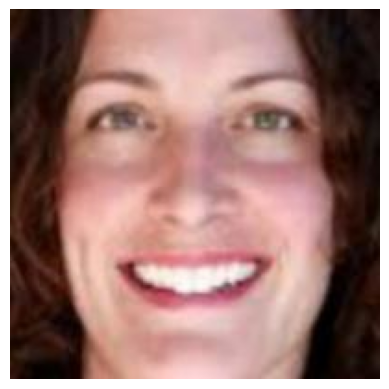

In [23]:
img = Image.open(df['image'][0])
plt.axis('off')
plt.imshow(img) # Semi-colon prevents the console to show anything else but the image

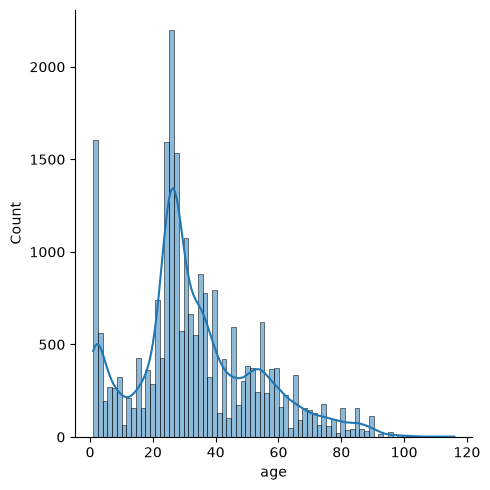

In [24]:
sns.displot(df['age'], kde=True)

Original labels sample: [39 23 26 31 42]
Mapped group indices sample: [5 4 4 5 5]
One-hot encoded targets shape: (23708, 8)


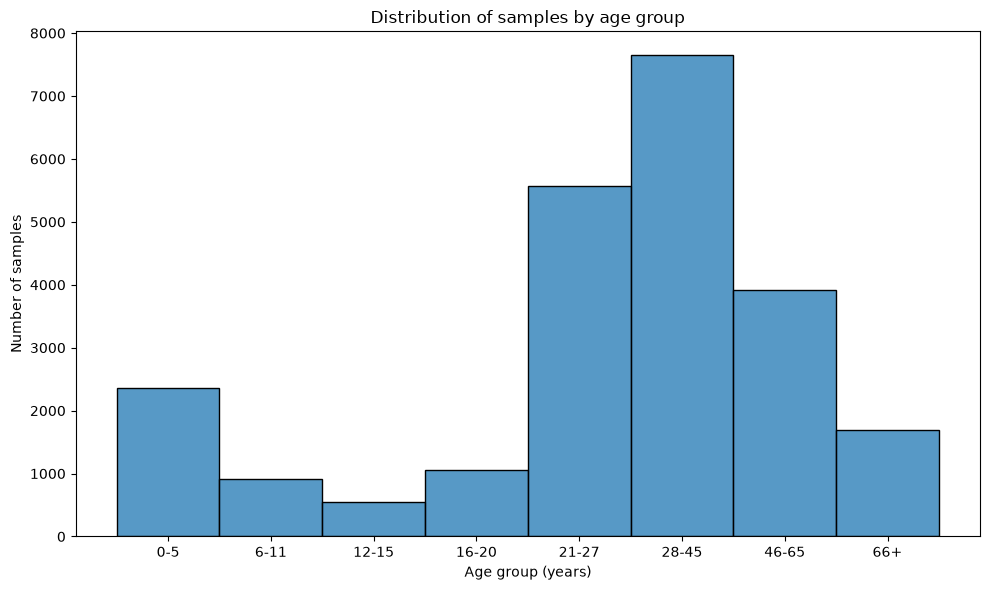

In [25]:
def map_age_to_group(age):
    if age <= 5: # 0-5
        return 0
    elif age <= 11: # 6-11
        return 1
    elif age <= 15: # 12-15
        return 2
    elif age <= 20: # 16-20
        return 3
    elif age <= 27:
        return 4
    elif age <= 45:
        return 5
    elif age <= 65:
        return 6
    else:
        return 7

# Map each age to its group index (0-9)
df['age_group'] = df['age'].apply(map_age_to_group)

# Convert indices to one-hot encoded representation
y_age_cat = to_categorical(df['age_group'], num_classes=8)

print("Original labels sample:", df['age'].values[:5])
print("Mapped group indices sample:", df['age_group'].values[:5])
print("One-hot encoded targets shape:", y_age_cat.shape)

age_group_labels = ["0-5", "6-11", "12-15", "16-20", "21-27", "28-45", "46-65", "66+"]
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="age_group", discrete=True)
plt.xticks(range(len(age_group_labels)), age_group_labels)
plt.xlabel("Age group (years)")
plt.ylabel("Number of samples")
plt.title("Distribution of samples by age group")
plt.tight_layout()

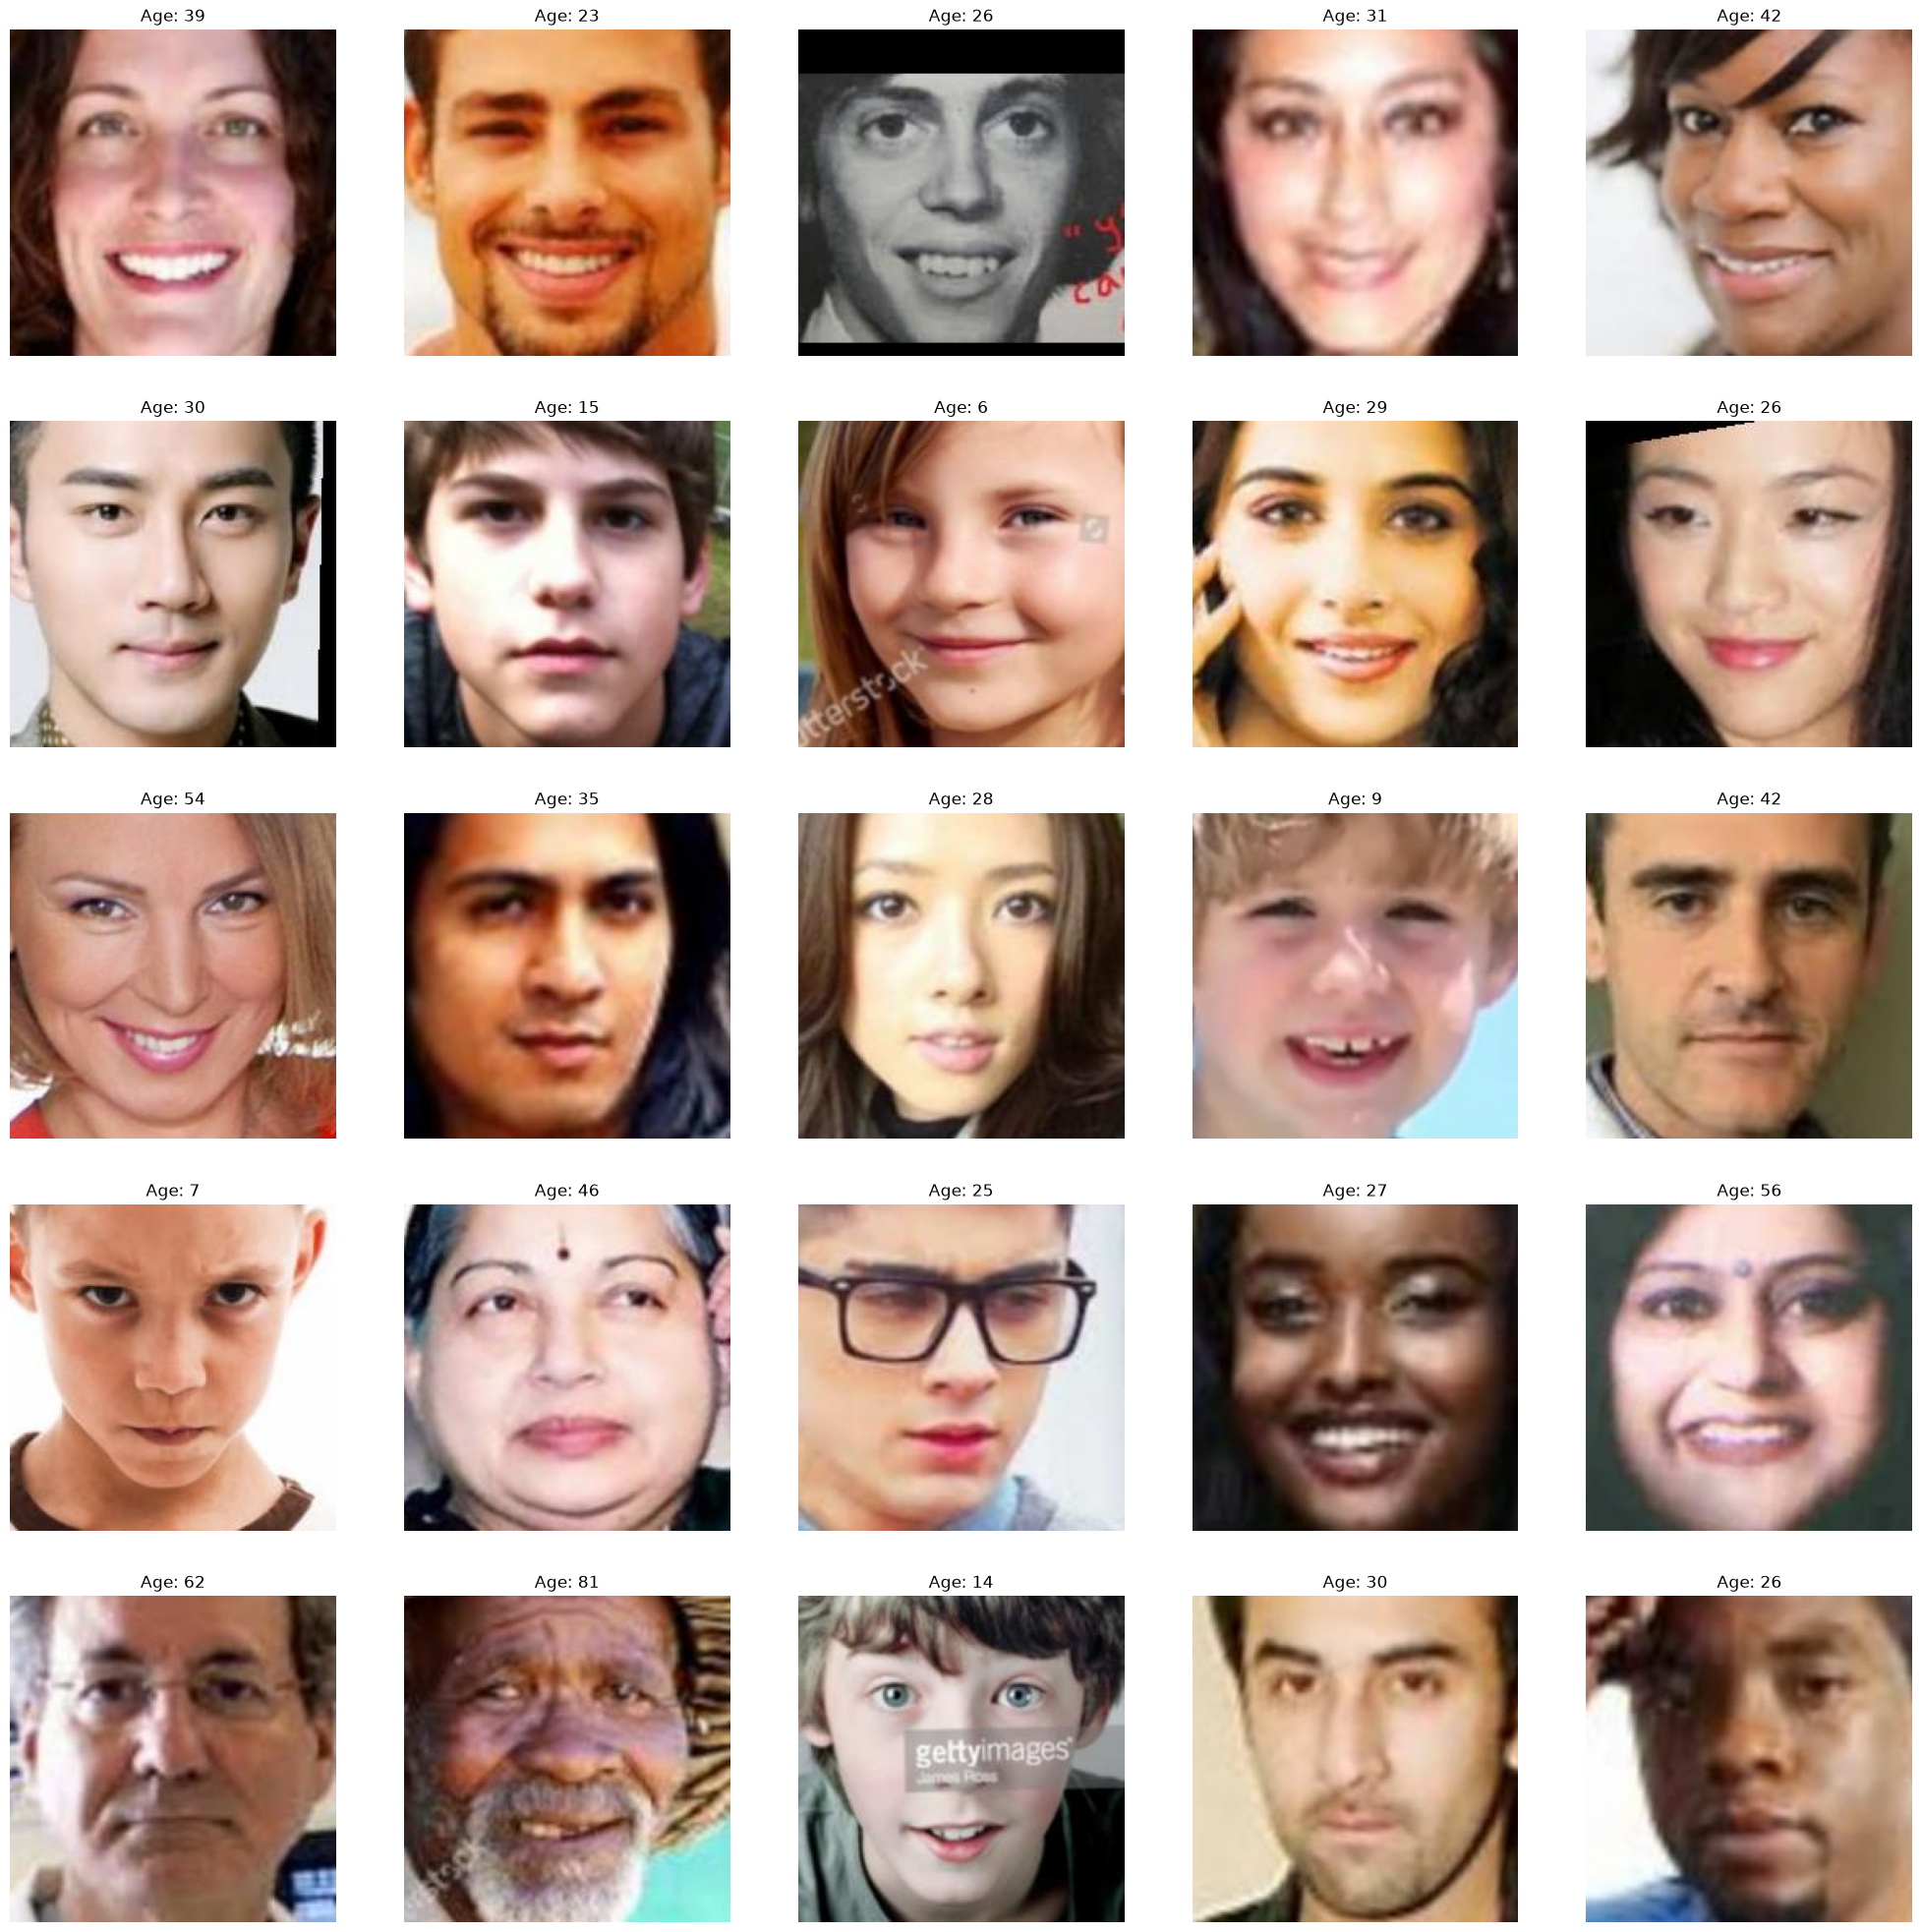

In [26]:
plt.figure(figsize=(25, 25))
files = df.iloc[0:25]
for index, file, age, age_group in files.itertuples():
    plt.subplot(5, 5, index+1)
    img = load_img(file)
    img = np.array(img)
    plt.imshow(img)
    plt.title(f"Age: {age}")
    plt.axis('off')

# Feature Extraction

In [27]:
def extract_features(images, size:int):
    features = []
    for image in tqdm(images):
        img = load_img(image, color_mode="grayscale")

        # Use Image.Resampling.LANCZOS instead of deprecated Image.ANTIALIAS
        resample_filter = Image.Resampling.LANCZOS if hasattr(Image, 'Resampling') else Image.ANTIALIAS
        img = img.resize((size, size), resample_filter)

        img = np.array(img)
        features.append(img)

    features = np.array(features)
    features = features.reshape(len(features), size, size, 1)

    return features

In [28]:
X = extract_features(df['image'], size=200)

  0%|          | 0/23708 [00:00<?, ?it/s]

In [29]:
X.shape

(23708, 200, 200, 1)

In [30]:
# Normalization
X = X.astype('float32') / 255.0

y_age = np.array(df['age'])

In [31]:
X_train, X_holdout, y_train, y_holdout, groups_train, groups_holdout, ages_train, ages_holdout = train_test_split(
    X,
    y_age_cat,
    df["age_group"].to_numpy(),
    y_age,
    test_size=0.2,
    stratify=df["age_group"],
    random_state=42,
)

X_val, X_test, y_val, y_test, ages_val, ages_test = train_test_split(
    X_holdout,
    y_holdout,
    ages_holdout,
    test_size=0.5,
    stratify=groups_holdout,
    random_state=42,
)

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")

Train: 18966 | Validation: 2371 | Test: 2371


In [37]:
simple_model = Sequential()

simple_model.add(Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(200, 200, 1)))
simple_model.add(MaxPooling2D(pool_size=(2, 2)))
simple_model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
simple_model.add(MaxPooling2D(pool_size=(2, 2)))
simple_model.add(Conv2D(128, (3, 3), padding='same', activation='relu'))
simple_model.add(MaxPooling2D(pool_size=(2, 2)))
simple_model.add(Conv2D(256, (3, 3), padding='same', activation='relu'))
simple_model.add(MaxPooling2D(pool_size=(2, 2)))

simple_model.add(GlobalAveragePooling2D())
simple_model.add(Dense(128, activation='relu'))
simple_model.add(Dropout(.3))
simple_model.add(Dense(32, activation='relu'))
simple_model.add(Dropout(.3))
simple_model.add(Dense(8, activation='softmax'))

In [38]:
simple_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 200, 200, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 100, 100, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 50, 50, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 25, 25, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 425,128 (1.62 MB)

 Trainable params: 425,128 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
#plot_model(simple_model, dpi=64)

In [39]:
simple_model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)
# Add early stopping to prevent overfitting and save the best model
early_stop = EarlyStopping(
    monitor='val_loss',             # Monitor the validation loss
    patience=10,                    # Number of epochs to wait before stopping
    restore_best_weights=True,      # Restore the weights of the best epoch
    verbose=1                       # Print a message when early stopping is triggered
)


In [40]:
history = simple_model.fit(
    x=X_train,
    y=y_train,
    batch_size=64,
    epochs=20,
    callbacks=[early_stop],
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/20


I0000 00:00:1792141625.990710   45146 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_10713__.74
I0000 00:00:1792141626.056699   45146 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1792141626.243339   46563 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_1_6', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1792141627.143752   45146 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1792141627.276948   46566 subprocess_compilation.cc:348] ptxas warning : Registers are spilled

294/297 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.2946 - loss: 1.8004

I0000 00:00:1792141641.338320   45146 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_10713__.74


297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2947 - loss: 1.7998

I0000 00:00:1792141644.738751   45145 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
I0000 00:00:1792141645.922093   45145 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


297/297 ━━━━━━━━━━━━━━━━━━━━ 24s 46ms/step - accuracy: 0.2947 - loss: 1.7998 - val_accuracy: 0.3437 - val_loss: 1.6924
Epoch 2/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.3334 - loss: 1.6963 - val_accuracy: 0.3551 - val_loss: 1.6440
Epoch 3/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.3540 - loss: 1.6519 - val_accuracy: 0.3631 - val_loss: 1.6131
Epoch 4/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.3799 - loss: 1.5889 - val_accuracy: 0.4184 - val_loss: 1.4938
Epoch 5/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.4123 - loss: 1.4784 - val_accuracy: 0.4272 - val_loss: 1.4415
Epoch 6/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.4461 - loss: 1.3867 - val_accuracy: 0.4812 - val_loss: 1.2668
Epoch 7/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.4699 - loss: 1.3105 - val_accuracy: 0.4918 - val_loss: 1.2292
Epoch 8/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.4852 - loss: 1.2664 - val_accuracy: 0.51

# Visualize intermediate outputs of simple_model

In [41]:
# 1. Select convolutional, pooling, and dense layers
visualization_layers = [
    layer for layer in simple_model.layers
    if isinstance(layer, (
        Conv2D,
        MaxPooling2D,
        Flatten,
        Dense
    ))
]

# 2. Create a model that returns all selected layer outputs
visualization_model = tf.keras.Model(
    inputs=simple_model.inputs,
    outputs=[layer.output for layer in visualization_layers]
)


# Evaluate the model

In [42]:
score = simple_model.evaluate(X_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

I0000 00:00:1792141785.679713   45148 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


Test loss: 1.0329526662826538
Test accuracy: 0.5773935317993164


# Predict on Random images

E0000 00:00:1792141787.149191    1262 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


Random IDs: [1851, 2196, 1696, 210]
Predicted age groups: ['28-45', '28-45', '46-65', '28-45']
Actual age groups: ['21-27', '28-45', '46-65', '46-65']


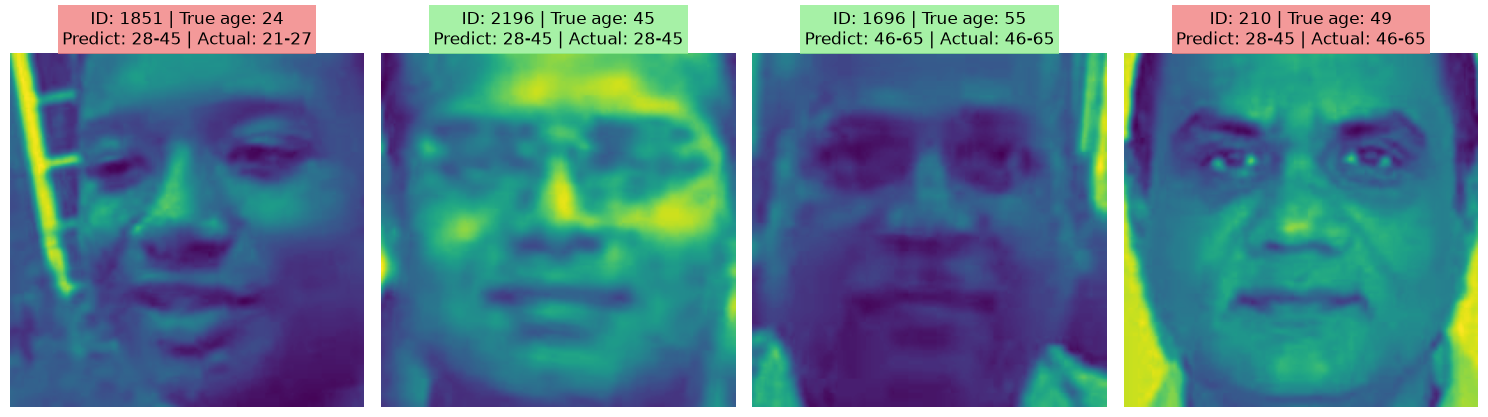

In [43]:
random_ids = np.random.choice(len(X_test), size=4, replace=False)

predictions = simple_model.predict(X_test[random_ids], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test[random_ids], axis=1)

print('Random IDs:', random_ids.tolist())
print('Predicted age groups:', [age_group_labels[label] for label in predicted_labels])
print('Actual age groups:', [age_group_labels[label] for label in actual_labels])

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, image_id, predicted_label, actual_label, true_age in zip(axes.flat, random_ids, predicted_labels, actual_labels, ages_test[random_ids]):
    ax.imshow(X_test[image_id])
    match_color = 'lightgreen' if predicted_label == actual_label else 'lightcoral'
    ax.set_facecolor(match_color)
    title = ax.set_title(
        f'ID: {image_id} | True age: {true_age}\nPredict: {age_group_labels[predicted_label]} | Actual: {age_group_labels[actual_label]}'
    )
    title.set_bbox(dict(facecolor=match_color, alpha=0.8, edgecolor='none', pad=3))
    ax.axis('off')

plt.tight_layout()
plt.show()

Test image ID: 1851


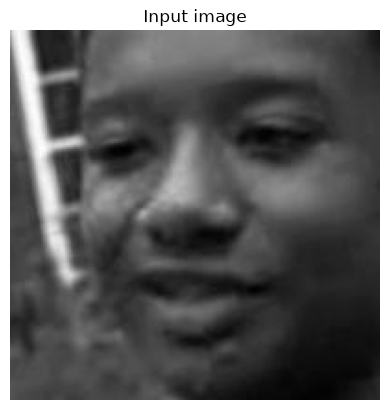

/home/sisi/projects/age-estimation/.venv/lib/python3.13/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_120']
Received: inputs=Tensor(shape=(1, 200, 200, 1))
  warnings.warn(msg)


conv2d_4: (200, 200, 32)


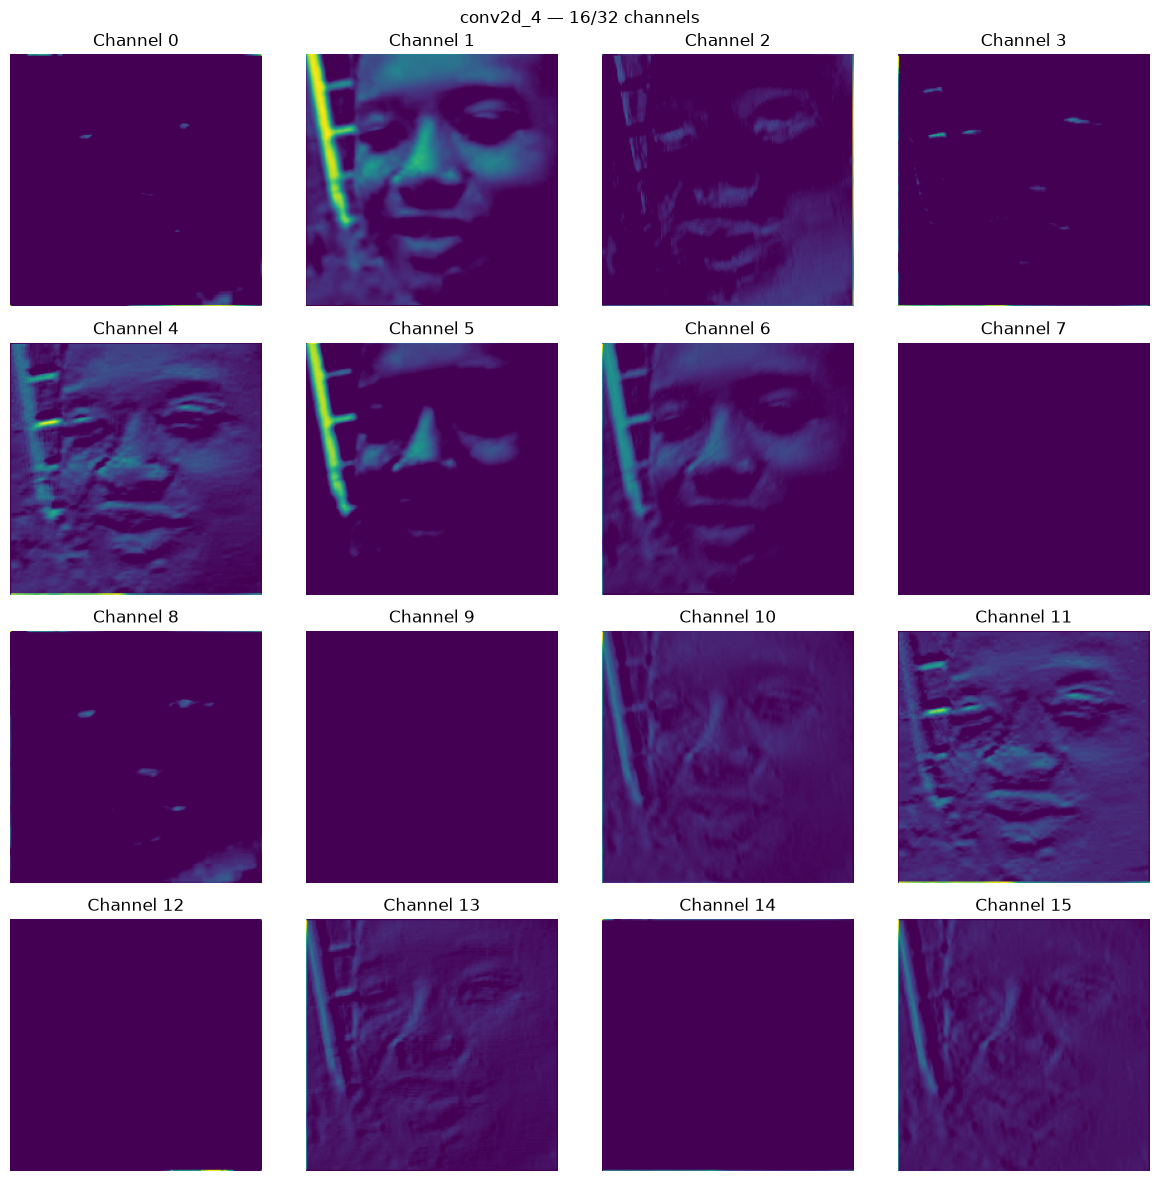

max_pooling2d_4: (100, 100, 32)


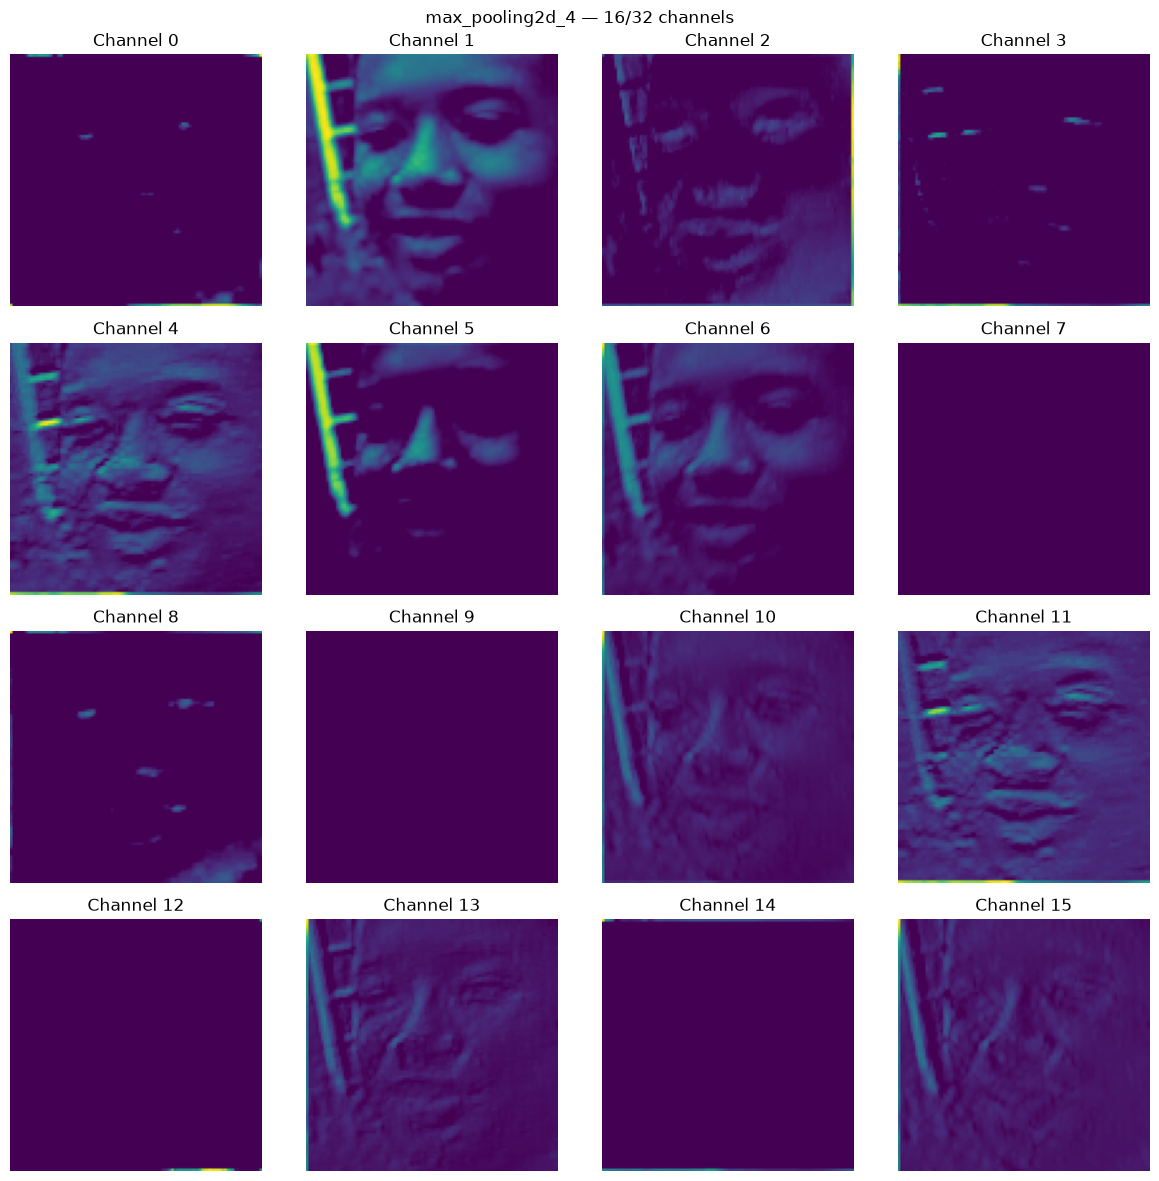

conv2d_5: (100, 100, 64)


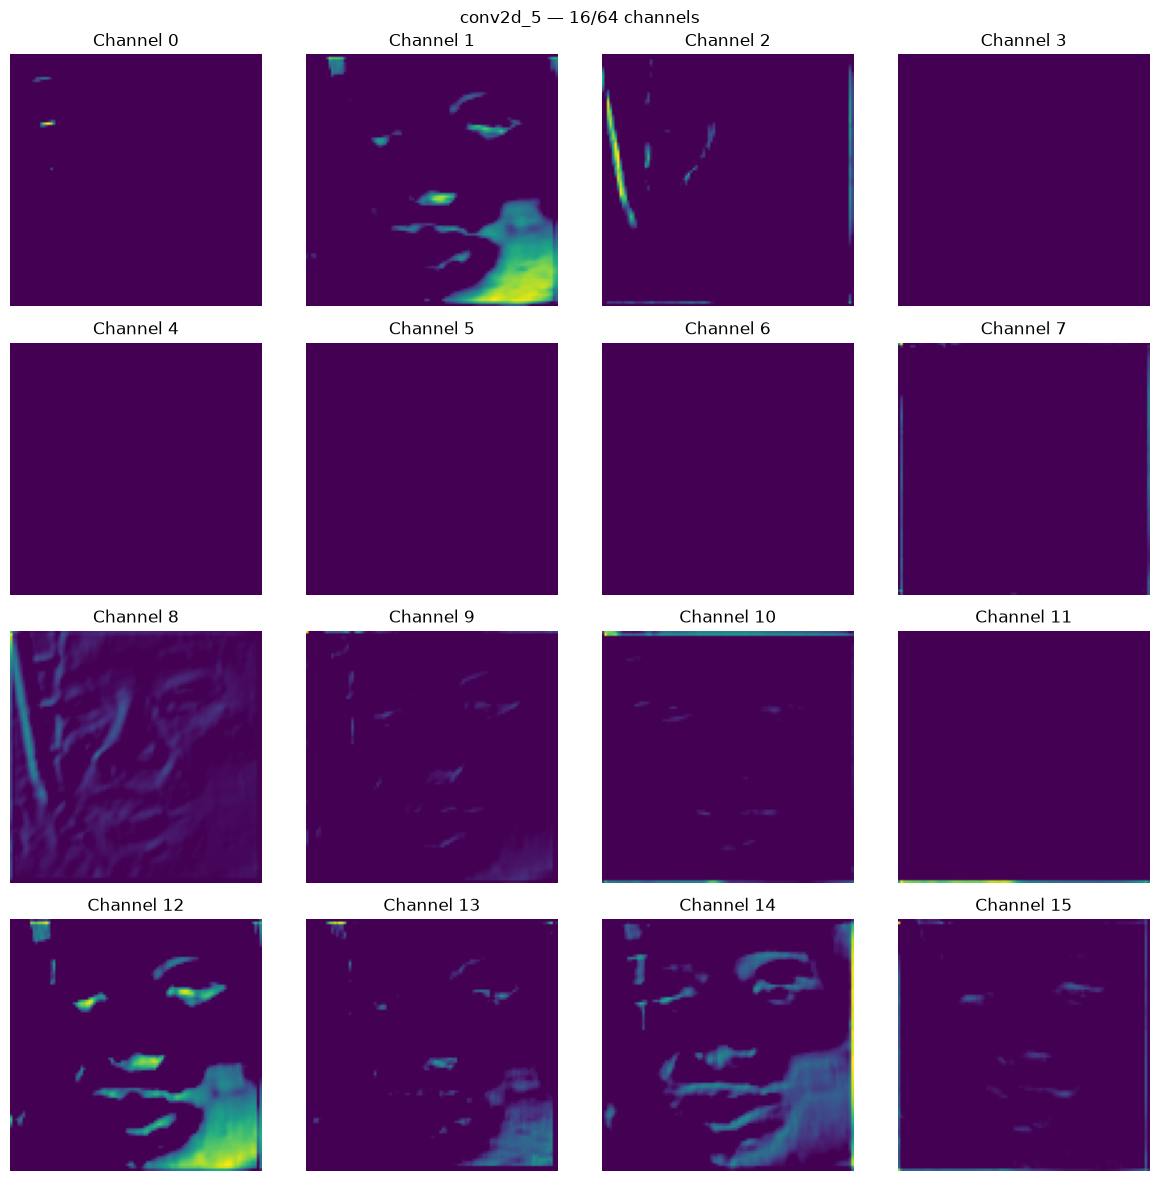

max_pooling2d_5: (50, 50, 64)


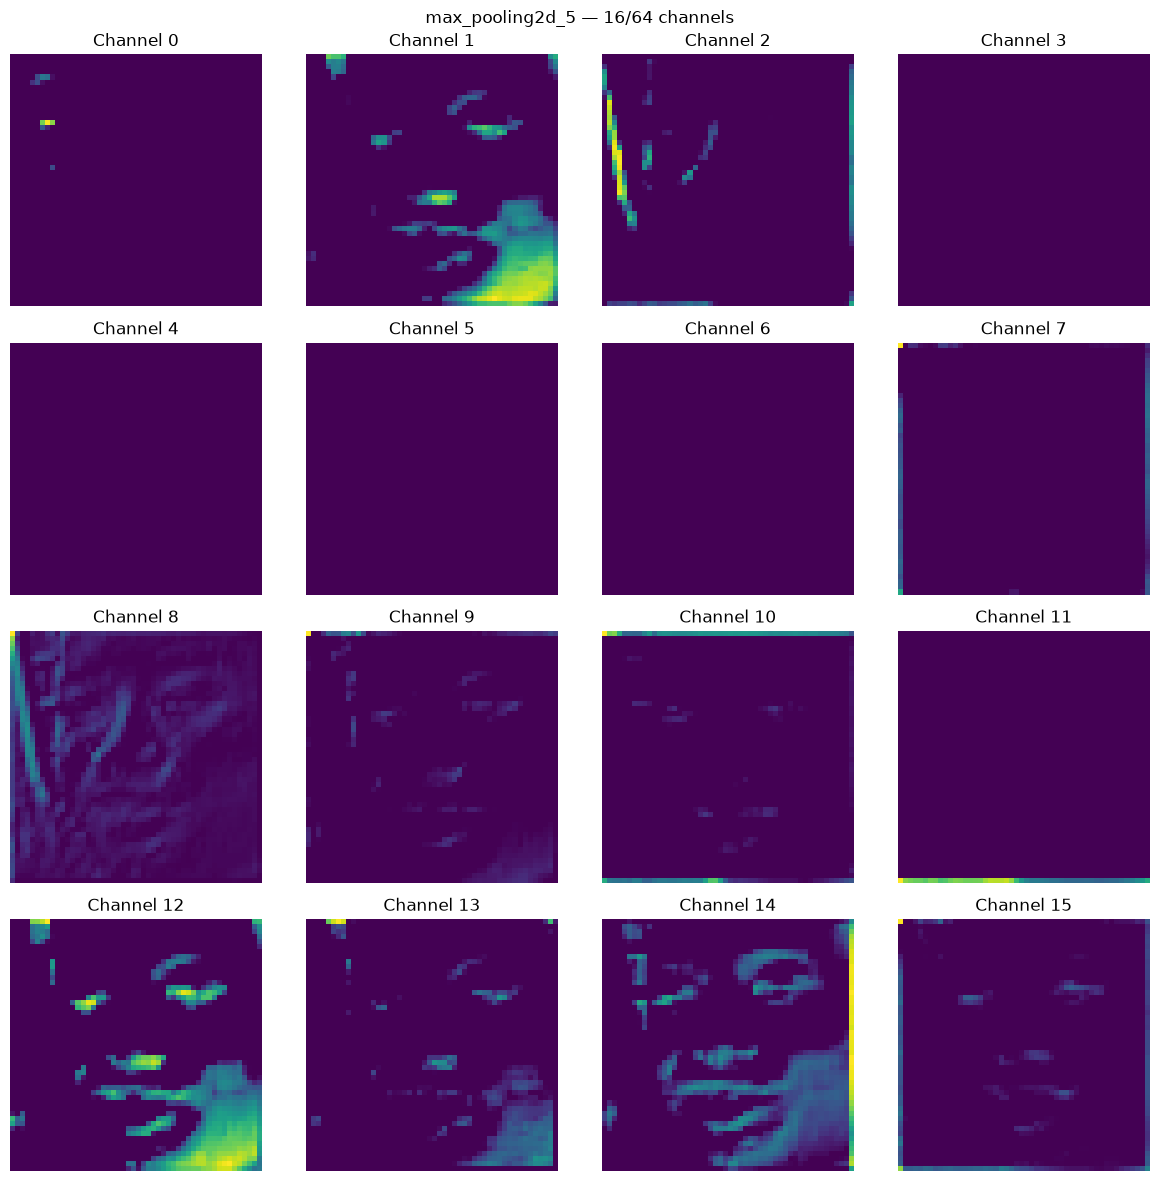

conv2d_6: (50, 50, 128)


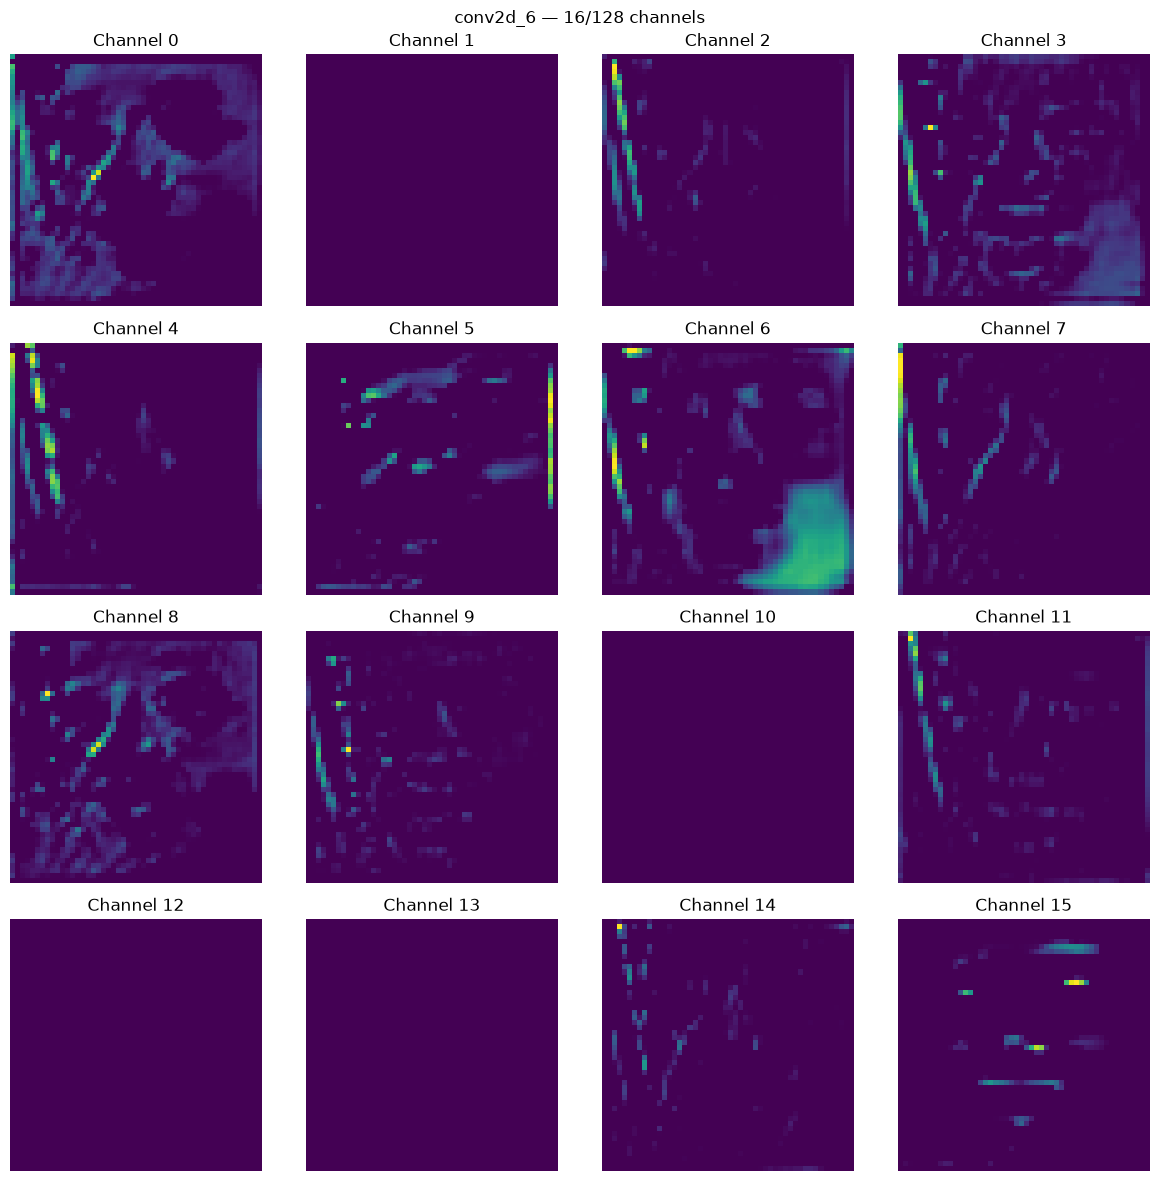

max_pooling2d_6: (25, 25, 128)


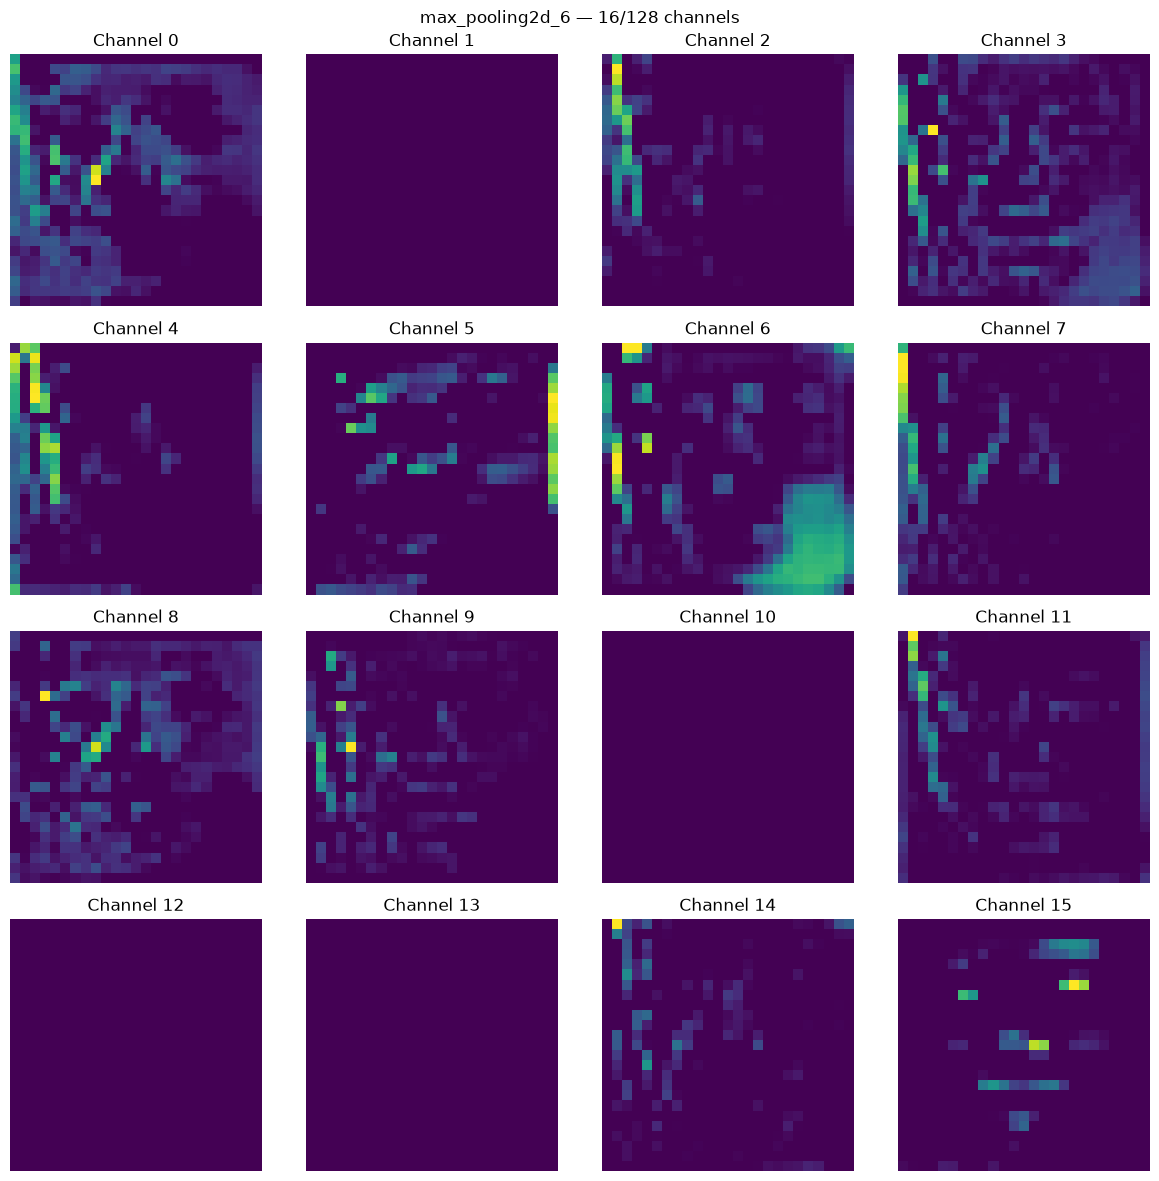

conv2d_7: (25, 25, 256)


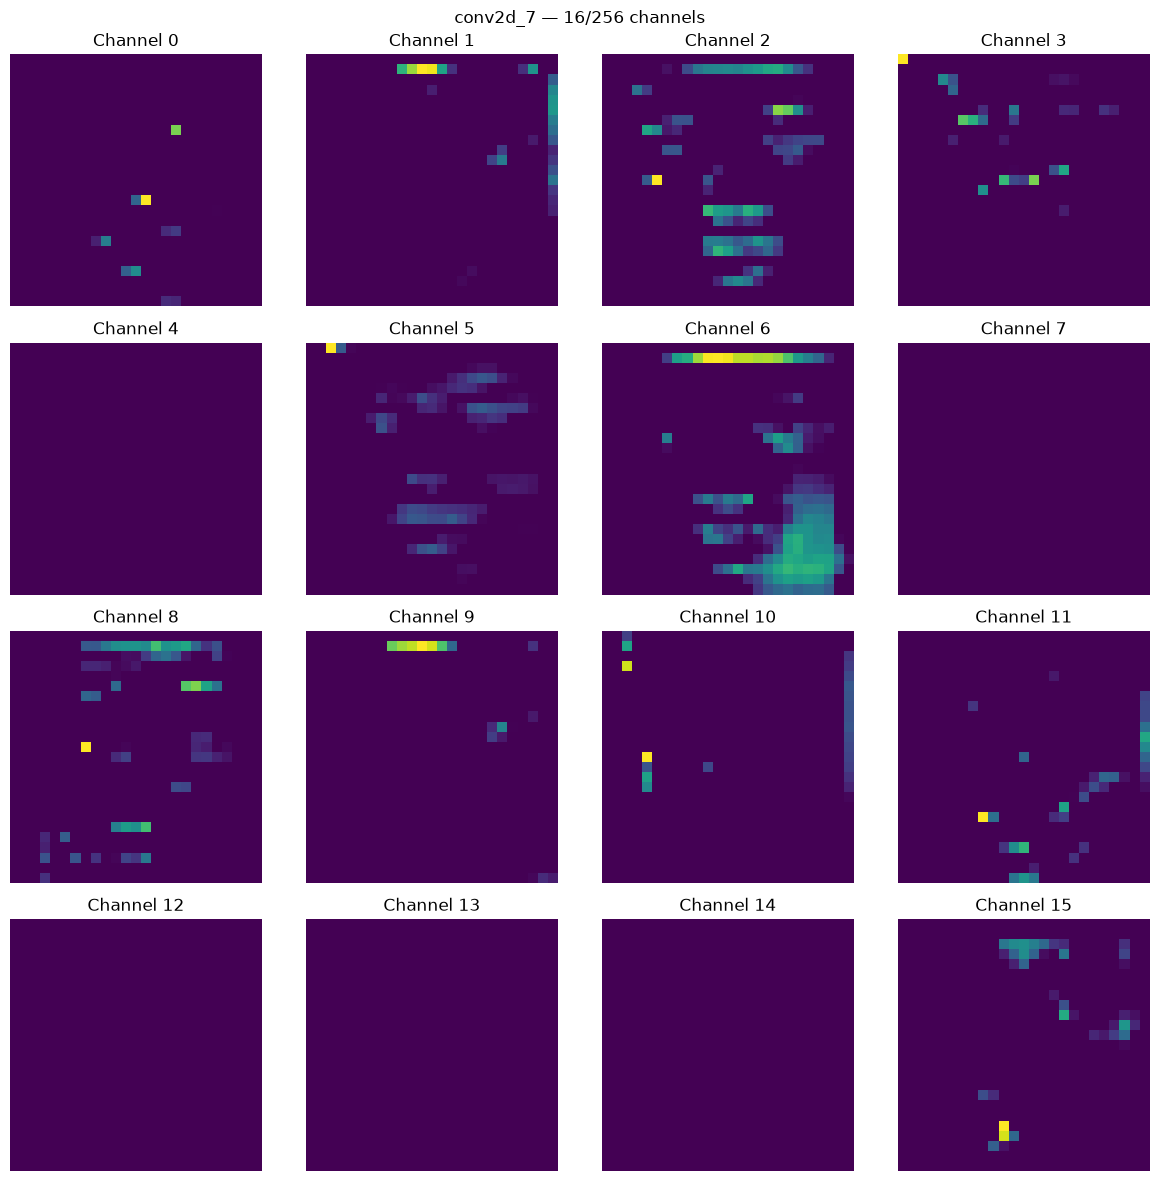

max_pooling2d_7: (12, 12, 256)


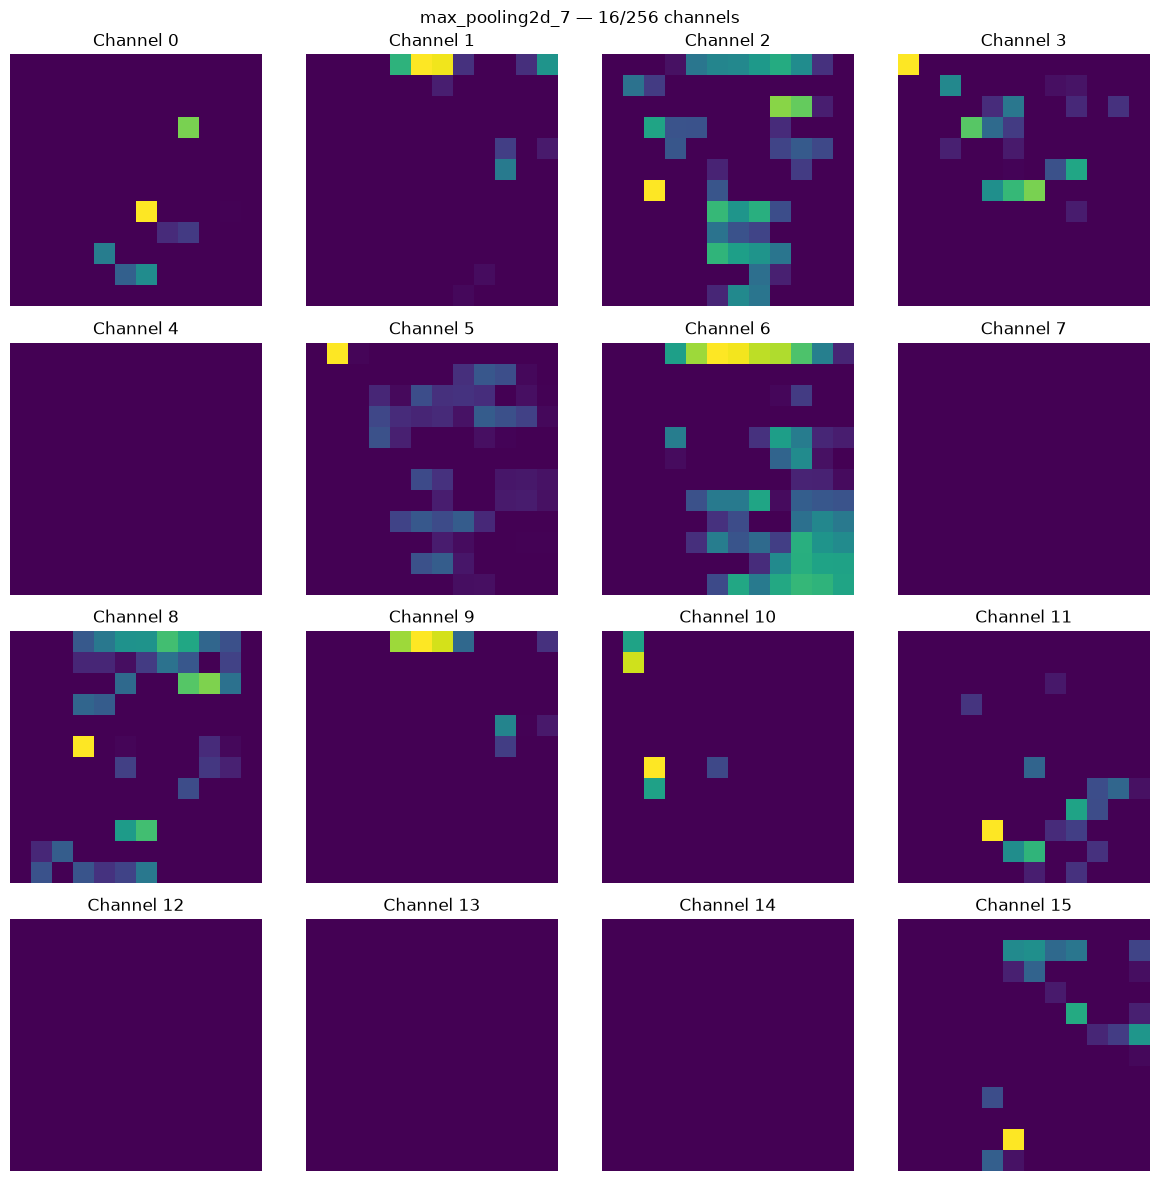

dense_3: (128,)


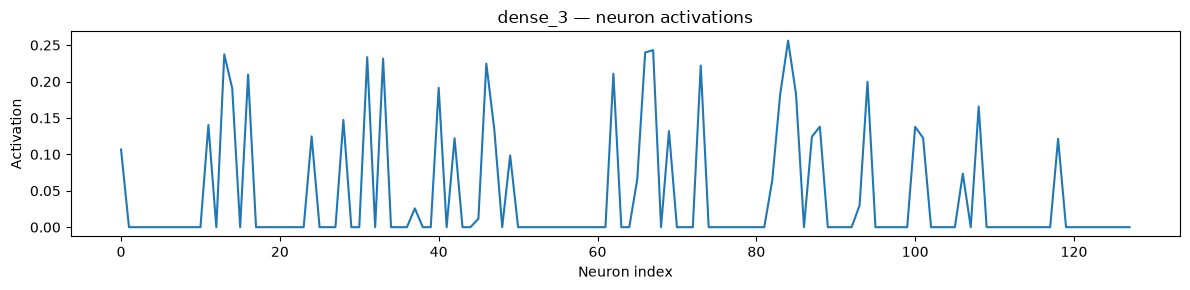

dense_4: (32,)


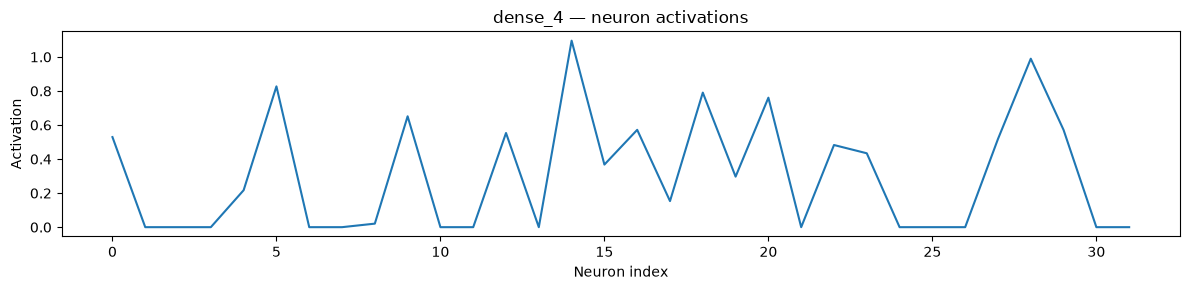

dense_5: (8,)


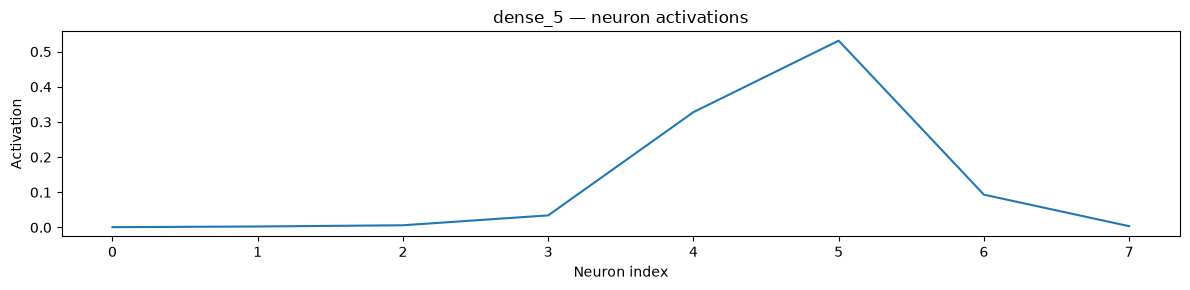

In [44]:
def visualize_layer_outputs(model, image, max_channels=16):
    # image shape: (100, 100, 1)
    image_batch = np.expand_dims(image, axis=0)

    outputs = model(image_batch, training=False)

    for layer, output in zip(visualization_layers, outputs):
        values = output[0].numpy()

        print(f"{layer.name}: {values.shape}")

        if values.ndim == 3:
            # Conv2D / MaxPooling2D: (H, W, C)
            n_channels = min(values.shape[-1], max_channels)
            n_cols = 4
            n_rows = int(np.ceil(n_channels / n_cols))

            fig, axes = plt.subplots(
                n_rows, n_cols,
                figsize=(12, 3 * n_rows),
                squeeze=False
            )

            for i, ax in enumerate(axes.flat):
                if i < n_channels:
                    ax.imshow(values[:, :, i], cmap="viridis")
                    ax.set_title(f"Channel {i}")
                ax.axis("off")

            fig.suptitle(
                f"{layer.name} — {n_channels}/{values.shape[-1]} channels"
            )
            plt.tight_layout()
            plt.show()

        elif values.ndim == 1:
            # Flatten / Dense: display neuron activations
            fig, ax = plt.subplots(figsize=(12, 3))
            ax.plot(values)
            ax.set_title(f"{layer.name} — neuron activations")
            ax.set_xlabel("Neuron index")
            ax.set_ylabel("Activation")
            plt.tight_layout()
            plt.show()


# Use an image from the existing test set
image_id = int(random_ids[0])

print("Test image ID:", image_id)
plt.imshow(X_test[image_id, :, :, 0], cmap="gray")
plt.title("Input image")
plt.axis("off")
plt.show()

visualize_layer_outputs(
    visualization_model,
    X_test[image_id]
)


# Complex CNN with VGG16

In [45]:
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

In [46]:
IMG_SIZE = 128
BATCH_SIZE = 64

test_datagen = ImageDataGenerator()

train_generator = train_datagen.flow(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_generator = test_datagen.flow(
    X_test, y_test,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [47]:
vgg_base = VGG16(
    weights='imagenet', 
    include_top=False, 
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
vgg_base.trainable = False  # Freeze base model

vgg_model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
    layers.Resizing(IMG_SIZE, IMG_SIZE),    # Resize with batch
    layers.Lambda(tf.image.grayscale_to_rgb), # Expand only the current batch for VGG16
    layers.Rescaling(255.0),                 # X is normalized to [0, 1] above
    layers.Lambda(vgg_preprocess),          # Applied onto the input before the backbone 
    vgg_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(8, activation='softmax')
])

vgg_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,072 (56.64 MB)

 Trainable params: 133,384 (521.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [48]:
vgg_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'])

In [49]:
history_vgg = vgg_model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20


I0000 00:00:1792141794.532124    1262 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
W0000 00:00:1792141795.428630   45148 assert_op.cc:39] Ignoring Assert operator sequential_2_1/lambda_1/grayscale_to_rgb/assert_equal_1/Assert/Assert
W0000 00:00:1792141795.428724   45148 assert_op.cc:39] Ignoring Assert operator sequential_2_1/lambda_1/grayscale_to_rgb/assert_greater_equal/Assert/Assert
I0000 00:00:1792141795.727102   45148 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_42535__.81
I0000 00:00:1792141797.404853   45148 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


189/297 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.3743 - loss: 2.7311

W0000 00:00:1792141813.546930   45146 assert_op.cc:39] Ignoring Assert operator sequential_2_1/lambda_1/grayscale_to_rgb/assert_equal_1/Assert/Assert
W0000 00:00:1792141813.546979   45146 assert_op.cc:39] Ignoring Assert operator sequential_2_1/lambda_1/grayscale_to_rgb/assert_greater_equal/Assert/Assert
I0000 00:00:1792141813.853985   45146 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_42535__.81


297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.4058 - loss: 2.2335

W0000 00:00:1792141825.762400   45148 assert_op.cc:39] Ignoring Assert operator sequential_2_1/lambda_1/grayscale_to_rgb/assert_equal_1/Assert/Assert
W0000 00:00:1792141825.762563   45148 assert_op.cc:39] Ignoring Assert operator sequential_2_1/lambda_1/grayscale_to_rgb/assert_greater_equal/Assert/Assert
W0000 00:00:1792141827.305382   45144 assert_op.cc:39] Ignoring Assert operator sequential_2_1/lambda_1/grayscale_to_rgb/assert_equal_1/Assert/Assert
W0000 00:00:1792141827.305428   45144 assert_op.cc:39] Ignoring Assert operator sequential_2_1/lambda_1/grayscale_to_rgb/assert_greater_equal/Assert/Assert


297/297 ━━━━━━━━━━━━━━━━━━━━ 35s 100ms/step - accuracy: 0.4058 - loss: 2.2335 - val_accuracy: 0.5133 - val_loss: 1.2123
Epoch 2/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 24s 81ms/step - accuracy: 0.4871 - loss: 1.2818 - val_accuracy: 0.5251 - val_loss: 1.1739
Epoch 3/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 27s 91ms/step - accuracy: 0.5033 - loss: 1.2315 - val_accuracy: 0.5318 - val_loss: 1.1360
Epoch 4/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 25s 83ms/step - accuracy: 0.5130 - loss: 1.2051 - val_accuracy: 0.5453 - val_loss: 1.1224
Epoch 5/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 24s 79ms/step - accuracy: 0.5189 - loss: 1.1846 - val_accuracy: 0.5458 - val_loss: 1.1102
Epoch 6/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 28s 94ms/step - accuracy: 0.5238 - loss: 1.1735 - val_accuracy: 0.5500 - val_loss: 1.1138
Epoch 7/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 23s 76ms/step - accuracy: 0.5234 - loss: 1.1690 - val_accuracy: 0.5462 - val_loss: 1.1228
Epoch 8/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 24s 79ms/step - accuracy: 0.5273 - loss: 1.1642 - val_accura

In [50]:
vgg_test_loss, vgg_test_acc = vgg_model.evaluate(test_generator)

print(f"VGG16 test accuracy: {vgg_test_acc:.4f}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5529 - loss: 1.0870
VGG16 test accuracy: 0.5529
